In [1]:
import os

print(os.listdir("."))

['brisc2025.zip', 'Krittika_BRISC_Verification.ipynb', '.ipynb_checkpoints']


In [2]:
import zipfile
import os

zip_path = "brisc2025.zip"
extract_path = "data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("BRISC dataset extracted successfully!")

BRISC dataset extracted successfully!


In [3]:
print(os.listdir("data"))

['brisc2025']


In [4]:
for root, dirs, files in os.walk("data"):
    print(root, ":", len(files), "files")

data : 0 files
data/brisc2025 : 5 files
data/brisc2025/segmentation_task : 0 files
data/brisc2025/segmentation_task/test : 0 files
data/brisc2025/segmentation_task/test/images : 860 files
data/brisc2025/segmentation_task/test/masks : 860 files
data/brisc2025/segmentation_task/train : 0 files
data/brisc2025/segmentation_task/train/images : 3933 files
data/brisc2025/segmentation_task/train/masks : 3933 files
data/brisc2025/classification_task : 0 files
data/brisc2025/classification_task/test : 0 files
data/brisc2025/classification_task/test/pituitary : 300 files
data/brisc2025/classification_task/test/no_tumor : 140 files
data/brisc2025/classification_task/test/glioma : 254 files
data/brisc2025/classification_task/test/meningioma : 306 files
data/brisc2025/classification_task/train : 0 files
data/brisc2025/classification_task/train/pituitary : 1457 files
data/brisc2025/classification_task/train/no_tumor : 1067 files
data/brisc2025/classification_task/train/glioma : 1147 files
data/brisc2

In [6]:
from pathlib import Path

DATASET_ROOT = Path("data/brisc2025")

CLASSIFICATION_ROOT = DATASET_ROOT / "classification_task"

print("Classification path:", CLASSIFICATION_ROOT)
print("Path exists:", CLASSIFICATION_ROOT.exists())

Classification path: data/brisc2025/classification_task
Path exists: True


In [7]:

# Classification Dataset Count Verification

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

classification_counts = {}

for split in ["train", "test"]:
    split_path = CLASSIFICATION_ROOT / split

    if not split_path.exists():
        raise FileNotFoundError(f"Missing directory: {split_path}")

    classification_counts[split] = {}

    print(f"\n{split.upper()} SPLIT")
    print("-" * 40)

    total = 0

    for class_dir in sorted(split_path.iterdir()):
        if class_dir.is_dir():

            files = [
                f for f in class_dir.iterdir()
                if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
            ]

            count = len(files)

            classification_counts[split][class_dir.name] = count
            total += count

            print(f"{class_dir.name:<15}: {count}")

    print(f"{'TOTAL':<15}: {total}")



TRAIN SPLIT
----------------------------------------
glioma         : 1147
meningioma     : 1329
no_tumor       : 1067
pituitary      : 1457
TOTAL          : 5000

TEST SPLIT
----------------------------------------
glioma         : 254
meningioma     : 306
no_tumor       : 140
pituitary      : 300
TOTAL          : 1000


In [9]:
from pathlib import Path

DATASET_ROOT = Path("data/brisc2025")

SEGMENTATION_ROOT = DATASET_ROOT / "segmentation_task"

print("Segmentation path:", SEGMENTATION_ROOT)
print("Path exists:", SEGMENTATION_ROOT.exists())

Segmentation path: data/brisc2025/segmentation_task
Path exists: True


In [10]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

for split in ["train", "test"]:
    images_path = SEGMENTATION_ROOT / split / "images"
    masks_path = SEGMENTATION_ROOT / split / "masks"

    image_files = {
        f.name for f in images_path.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    }

    mask_files = {
        f.name for f in masks_path.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    }

    print(f"\n{split.upper()} SPLIT")
    print("-" * 40)
    print("Images:", len(image_files))
    print("Masks:", len(mask_files))
    print("Missing masks:", len(image_files - mask_files))
    print("Missing images:", len(mask_files - image_files))
    print("Exact filename pairing:", image_files == mask_files)


TRAIN SPLIT
----------------------------------------
Images: 3933
Masks: 3933
Missing masks: 3933
Missing images: 3933
Exact filename pairing: False

TEST SPLIT
----------------------------------------
Images: 860
Masks: 860
Missing masks: 860
Missing images: 860
Exact filename pairing: False


In [11]:
for split in ["train", "test"]:

    images_path = SEGMENTATION_ROOT / split / "images"
    masks_path = SEGMENTATION_ROOT / split / "masks"

    image_files = sorted([
        f.name for f in images_path.iterdir()
        if f.is_file()
    ])

    mask_files = sorted([
        f.name for f in masks_path.iterdir()
        if f.is_file()
    ])

    print(f"\n{split.upper()} SPLIT")
    print("\nFirst 10 MRI image filenames:")
    print(image_files[:10])

    print("\nFirst 10 mask filenames:")
    print(mask_files[:10])


TRAIN SPLIT

First 10 MRI image filenames:
['brisc2025_train_00001_gl_ax_t1.jpg', 'brisc2025_train_00002_gl_ax_t1.jpg', 'brisc2025_train_00003_gl_ax_t1.jpg', 'brisc2025_train_00004_gl_ax_t1.jpg', 'brisc2025_train_00005_gl_ax_t1.jpg', 'brisc2025_train_00006_gl_ax_t1.jpg', 'brisc2025_train_00007_gl_ax_t1.jpg', 'brisc2025_train_00008_gl_ax_t1.jpg', 'brisc2025_train_00009_gl_ax_t1.jpg', 'brisc2025_train_00010_gl_ax_t1.jpg']

First 10 mask filenames:
['brisc2025_train_00001_gl_ax_t1.png', 'brisc2025_train_00002_gl_ax_t1.png', 'brisc2025_train_00003_gl_ax_t1.png', 'brisc2025_train_00004_gl_ax_t1.png', 'brisc2025_train_00005_gl_ax_t1.png', 'brisc2025_train_00006_gl_ax_t1.png', 'brisc2025_train_00007_gl_ax_t1.png', 'brisc2025_train_00008_gl_ax_t1.png', 'brisc2025_train_00009_gl_ax_t1.png', 'brisc2025_train_00010_gl_ax_t1.png']

TEST SPLIT

First 10 MRI image filenames:
['brisc2025_test_00001_gl_ax_t1.jpg', 'brisc2025_test_00002_gl_ax_t1.jpg', 'brisc2025_test_00003_gl_ax_t1.jpg', 'brisc2025_te

In [12]:

for split in ["train", "test"]:

    images_path = SEGMENTATION_ROOT / split / "images"
    masks_path = SEGMENTATION_ROOT / split / "masks"

    image_stems = {
        f.stem for f in images_path.iterdir()
        if f.is_file() and f.suffix.lower() in {".jpg", ".jpeg", ".png"}
    }

    mask_stems = {
        f.stem for f in masks_path.iterdir()
        if f.is_file() and f.suffix.lower() in {".jpg", ".jpeg", ".png"}
    }

    print(f"\n{split.upper()} SPLIT")
    print("-" * 40)
    print("MRI images:", len(image_stems))
    print("Masks:", len(mask_stems))
    print("Missing masks:", len(image_stems - mask_stems))
    print("Missing images:", len(mask_stems - image_stems))
    print("Filename pairing:", image_stems == mask_stems)



TRAIN SPLIT
----------------------------------------
MRI images: 3933
Masks: 3933
Missing masks: 0
Missing images: 0
Filename pairing: True

TEST SPLIT
----------------------------------------
MRI images: 860
Masks: 860
Missing masks: 0
Missing images: 0
Filename pairing: True


In [13]:
#File Extension Inspection

from collections import Counter

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

print("CLASSIFICATION FILE EXTENSIONS")
print("-" * 40)

for split in ["train", "test"]:
    extensions = Counter()

    for class_dir in (CLASSIFICATION_ROOT / split).iterdir():
        if class_dir.is_dir():
            for file in class_dir.iterdir():
                if file.is_file():
                    extensions[file.suffix.lower()] += 1

    print(f"{split.capitalize()}:", dict(extensions))
    unexpected = set(extensions) - IMAGE_EXTENSIONS
    print("Unexpected extensions:", unexpected)


print("\nSEGMENTATION FILE EXTENSIONS")
print("-" * 40)

for split in ["train", "test"]:
    image_extensions = Counter(
        f.suffix.lower()
        for f in (SEGMENTATION_ROOT / split / "images").iterdir()
        if f.is_file()
    )

    mask_extensions = Counter(
        f.suffix.lower()
        for f in (SEGMENTATION_ROOT / split / "masks").iterdir()
        if f.is_file()
    )

    print(f"\n{split.upper()}")
    print("Images:", dict(image_extensions))
    print("Masks :", dict(mask_extensions))
    print("Unexpected image extensions:",
          set(image_extensions) - IMAGE_EXTENSIONS)
    print("Unexpected mask extensions:",
          set(mask_extensions) - IMAGE_EXTENSIONS)


CLASSIFICATION FILE EXTENSIONS
----------------------------------------
Train: {'.jpg': 5000}
Unexpected extensions: set()
Test: {'.jpg': 1000}
Unexpected extensions: set()

SEGMENTATION FILE EXTENSIONS
----------------------------------------

TRAIN
Images: {'.jpg': 3933}
Masks : {'.png': 3933}
Unexpected image extensions: set()
Unexpected mask extensions: set()

TEST
Images: {'.jpg': 860}
Masks : {'.png': 860}
Unexpected image extensions: set()
Unexpected mask extensions: set()


In [14]:
#Segmentation Image Mask PAiring Verification

def check_image_mask_pairs(split):

    images_dir = SEGMENTATION_ROOT / split / "images"
    masks_dir = SEGMENTATION_ROOT / split / "masks"

    IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

    image_stems = {
        f.stem for f in images_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    }

    mask_stems = {
        f.stem for f in masks_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    }

    missing_masks = sorted(image_stems - mask_stems)
    missing_images = sorted(mask_stems - image_stems)

    print(f"\n{split.upper()} SPLIT")
    print("-" * 40)
    print("MRI images:", len(image_stems))
    print("Masks:", len(mask_stems))
    print("Images without masks:", len(missing_masks))
    print("Masks without images:", len(missing_images))

    if not missing_masks and not missing_images:
        print("Pairing status: FILENAME MATCH")
    else:
        print("Pairing status: MISMATCH FOUND")
        print("Images without masks:", missing_masks[:10])
        print("Masks without images:", missing_images[:10])


check_image_mask_pairs("train")
check_image_mask_pairs("test")



TRAIN SPLIT
----------------------------------------
MRI images: 3933
Masks: 3933
Images without masks: 0
Masks without images: 0
Pairing status: FILENAME MATCH

TEST SPLIT
----------------------------------------
MRI images: 860
Masks: 860
Images without masks: 0
Masks without images: 0
Pairing status: FILENAME MATCH


In [15]:

# Verify readability of all classification images, segmentation images, and masks

from PIL import Image

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def check_readability(file_paths):
    bad_files = []

    for file_path in file_paths:
        try:
            with Image.open(file_path) as img:
                img.load()

        except Exception as e:
            bad_files.append((str(file_path), str(e)))

    return bad_files


# 1. Collect classification images

classification_files = []

for split in ["train", "test"]:
    split_dir = CLASSIFICATION_ROOT / split

    for class_dir in split_dir.iterdir():
        if class_dir.is_dir():
            classification_files.extend(
                f for f in class_dir.iterdir()
                if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
            )


# 2. Collect segmentation MRI images

segmentation_images = []

for split in ["train", "test"]:
    images_dir = SEGMENTATION_ROOT / split / "images"

    segmentation_images.extend(
        f for f in images_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )


# 3. Collect segmentation masks

segmentation_masks = []

for split in ["train", "test"]:
    masks_dir = SEGMENTATION_ROOT / split / "masks"

    segmentation_masks.extend(
        f for f in masks_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )


# 4. Perform readability checks

print("Checking classification images...")
bad_classification = check_readability(classification_files)

print("Checking segmentation images...")
bad_segmentation_images = check_readability(segmentation_images)

print("Checking segmentation masks...")
bad_segmentation_masks = check_readability(segmentation_masks)


# 5. Display final report

print("\nREADABILITY REPORT")
print("-" * 45)

print("Classification files checked:", len(classification_files))
print("Unreadable classification files:", len(bad_classification))

print("\nSegmentation images checked:", len(segmentation_images))
print("Unreadable segmentation images:", len(bad_segmentation_images))

print("\nSegmentation masks checked:", len(segmentation_masks))
print("Unreadable segmentation masks:", len(bad_segmentation_masks))


# 6. Display problematic files if any

all_bad_files = (
    bad_classification +
    bad_segmentation_images +
    bad_segmentation_masks
)

if all_bad_files:
    print("\nUNREADABLE FILE DETAILS:")
    for path, error in all_bad_files[:20]:
        print(path, "->", error)
else:
    print("\nPASS: All collected image files are readable.")


Checking classification images...
Checking segmentation images...
Checking segmentation masks...

READABILITY REPORT
---------------------------------------------
Classification files checked: 6000
Unreadable classification files: 0

Segmentation images checked: 4793
Unreadable segmentation images: 0

Segmentation masks checked: 4793
Unreadable segmentation masks: 0

PASS: All collected image files are readable.


In [20]:

# Inspect image dimensions and color modes of classification images, MRI images, and masks

from collections import Counter
from PIL import Image

def inspect_image_properties(file_paths):
    dimensions = Counter()
    modes = Counter()
    unreadable_files = []

    for file_path in file_paths:
        try:
            with Image.open(file_path) as img:
                img.load()
                dimensions[img.size] += 1
                modes[img.mode] += 1

        except Exception as e:
            unreadable_files.append((str(file_path), str(e)))

    return dimensions, modes, unreadable_files


# 1. Classification images
class_dimensions, class_modes, class_errors = inspect_image_properties(
    classification_files
)

# 2. Segmentation MRI images
seg_dimensions, seg_modes, seg_errors = inspect_image_properties(
    segmentation_images
)

# 3. Segmentation masks
mask_dimensions, mask_modes, mask_errors = inspect_image_properties(
    segmentation_masks
)


# 4. Display results
def display_properties(title, dimensions, modes, errors):

    print(f"\n{title}")
    print("-" * 45)

    print("Unique dimensions:", len(dimensions))

    print("Dimensions:")
    for size, count in dimensions.most_common():
        print(f"  {size}: {count}")

    print("\nImage modes:")
    for mode, count in modes.items():
        print(f"  {mode}: {count}")

    print("Unreadable files:", len(errors))


display_properties(
    "CLASSIFICATION IMAGES",
    class_dimensions, class_modes, class_errors
)

display_properties(
    "SEGMENTATION MRI IMAGES",
    seg_dimensions, seg_modes, seg_errors
)

display_properties(
    "SEGMENTATION MASKS",
    mask_dimensions, mask_modes, mask_errors
)



CLASSIFICATION IMAGES
---------------------------------------------
Unique dimensions: 183
Dimensions:
  (512, 512): 4881
  (369, 369): 363
  (216, 369): 354
  (256, 256): 32
  (187, 369): 21
  (225, 225): 20
  (202, 369): 19
  (210, 369): 12
  (236, 236): 11
  (442, 442): 10
  (554, 554): 5
  (455, 500): 5
  (201, 251): 5
  (210, 240): 4
  (200, 223): 4
  (212, 237): 4
  (341, 395): 4
  (213, 237): 3
  (474, 474): 2
  (236, 269): 2
  (233, 218): 2
  (200, 210): 2
  (733, 781): 2
  (338, 345): 2
  (318, 354): 2
  (252, 303): 2
  (234, 216): 2
  (480, 480): 2
  (507, 605): 2
  (369, 398): 2
  (312, 401): 2
  (226, 214): 2
  (232, 261): 2
  (416, 395): 2
  (300, 345): 2
  (239, 224): 2
  (214, 235): 2
  (291, 340): 2
  (315, 315): 2
  (411, 396): 2
  (200, 235): 2
  (313, 393): 2
  (305, 337): 2
  (304, 410): 2
  (201, 207): 2
  (341, 377): 2
  (212, 238): 2
  (208, 243): 2
  (273, 326): 2
  (209, 241): 2
  (366, 395): 2
  (530, 526): 2
  (491, 624): 2
  (206, 249): 2
  (374, 370): 2
  

In [21]:

# Verify that each segmentation MRI image and its corresponding mask have matching dimensions

from PIL import Image

def check_pair_dimensions(split):

    images_dir = SEGMENTATION_ROOT / split / "images"
    masks_dir = SEGMENTATION_ROOT / split / "masks"

    IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

    mismatches = []
    missing_masks = []
    unreadable_pairs = []

    image_files = sorted(
        f for f in images_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )

    for image_path in image_files:

        mask_path = masks_dir / f"{image_path.stem}.png"

        if not mask_path.exists():
            missing_masks.append(image_path.name)
            continue

        try:
            with Image.open(image_path) as img, Image.open(mask_path) as mask:

                img.load()
                mask.load()

                if img.size != mask.size:
                    mismatches.append({
                        "image": image_path.name,
                        "image_size": img.size,
                        "mask": mask_path.name,
                        "mask_size": mask.size
                    })

        except Exception as e:
            unreadable_pairs.append({
                "image": image_path.name,
                "error": str(e)
            })

    print(f"\n{split.upper()} SPLIT")
    print("-" * 45)
    print("MRI images:", len(image_files))
    print("Pairs checked:", len(image_files) - len(missing_masks) - len(unreadable_pairs))
    print("Missing masks:", len(missing_masks))
    print("Dimension mismatches:", len(mismatches))
    print("Unreadable pairs:", len(unreadable_pairs))

    if not missing_masks and not mismatches and not unreadable_pairs:
        print("Dimension status: ALL PAIRS MATCH")
    else:
        print("Dimension status: ISSUES FOUND")

    return mismatches, missing_masks, unreadable_pairs


train_dimension_results = check_pair_dimensions("train")
test_dimension_results = check_pair_dimensions("test")



TRAIN SPLIT
---------------------------------------------
MRI images: 3933
Pairs checked: 3933
Missing masks: 0
Dimension mismatches: 0
Unreadable pairs: 0
Dimension status: ALL PAIRS MATCH

TEST SPLIT
---------------------------------------------
MRI images: 860
Pairs checked: 860
Missing masks: 0
Dimension mismatches: 0
Unreadable pairs: 0
Dimension status: ALL PAIRS MATCH


In [ ]:
# Notebook 01 – BRISC Dataset Structure Inspection

## 1. Objective

The objective of this notebook was to inspect the BRISC 2025 brain MRI dataset, understand its directory structure, verify image counts, examine file formats and dimensions, and confirm the correct pairing of segmentation MRI images with their corresponding masks.

## 2. Dataset Organization

- Extracted the BRISC dataset into the project data directory.
- Inspected the classification and segmentation directory structures.
- Verified the training and testing folders.
- Identified the four classification categories: glioma, meningioma, pituitary and no-tumor.
- Identified separate image and mask folders for segmentation.

## 3. Classification Dataset Inspection

Verified a total of 6,000 classification images:

- Training images: 5,000
- Testing images: 1,000

The class distribution was inspected separately for the training and testing splits.

**Training distribution:**
- Glioma: 1,147
- Meningioma: 1,329
- No-tumor: 1,067
- Pituitary: 1,457

**Testing distribution:**
- Glioma: 254
- Meningioma: 306
- No-tumor: 140
- Pituitary: 300

## 4. Segmentation Dataset Inspection

Verified a total of 4,793 MRI images and 4,793 corresponding masks.

- Training MRI images: 3,933
- Testing MRI images: 860
- Training masks: 3,933
- Testing masks: 860

Initially, direct filename comparison showed mismatches because MRI images used the `.jpg` extension while masks used `.png`. Pairing was therefore verified using filename stems.

All 4,793 MRI-mask pairs were correctly matched.

## 5. File Format and Extension Inspection

- Classification images were stored in JPG format.
- Segmentation MRI images were stored in JPG format.
- Segmentation masks were stored in PNG format.
- No unexpected file extensions were detected.

## 6. Image Readability and Properties

All 15,586 dataset files were checked for readability.

- Unreadable classification images: 0
- Unreadable segmentation MRI images: 0
- Unreadable segmentation masks: 0

Image dimensions and colour modes were also examined.

- Classification images contained 183 distinct dimension combinations.
- Segmentation MRI images and masks contained 140 distinct dimension combinations.
- A large proportion of images had dimensions of 512 × 512 pixels.
- Classification and segmentation MRI images contained both grayscale and RGB formats.
- All segmentation masks were grayscale.

## 7. MRI-Mask Dimension Verification

Compared the dimensions of every segmentation MRI image with its corresponding mask.

- Total pairs checked: 4,793
- Missing masks: 0
- Missing MRI images: 0
- Dimension mismatches: 0
- Unreadable pairs: 0

All paired MRI images and masks had matching dimensions.

## 8. Conclusion

The BRISC 2025 dataset was successfully inspected and its directory structure, classification distribution, segmentation image-mask relationships, file formats, readability and image properties were verified.

The inspection confirmed that all expected dataset files were present and readable, and all segmentation MRI images had corresponding masks with matching dimensions.

No resizing, image conversion or modification of the original dataset files was performed during this structural inspection.

The results provide the foundation for the subsequent dataset integrity audit and exploratory data analysis.

In [ ]:
## PART 2 – BRISC Integrity and Leakage Checks

In [22]:
# Locate and verify the manifest files required for Notebook 02.

from pathlib import Path

print("Dataset location:", DATASET_ROOT.resolve())
print("Dataset folder exists:", DATASET_ROOT.exists())

print("\nManifest-related files found:")

manifest_files = sorted(DATASET_ROOT.glob("manifest*"))

for file in manifest_files:
    print("✔", file.name)

print("\nTotal manifest-related files:", len(manifest_files))

Dataset location: /Users/krittikaroy/Brain Tumor/data/brisc2025
Dataset folder exists: True

Manifest-related files found:
✔ manifest.csv
✔ manifest.csv.sha256
✔ manifest.json
✔ manifest.json.sha256

Total manifest-related files: 4


In [24]:
# Define the paths to the BRISC manifest files.

MANIFEST_CSV = DATASET_ROOT / "manifest.csv"
MANIFEST_JSON = DATASET_ROOT / "manifest.json"

print("CSV manifest exists:", MANIFEST_CSV.exists())
print("JSON manifest exists:", MANIFEST_JSON.exists())

CSV manifest exists: True
JSON manifest exists: True


In [25]:
# Load and inspect the BRISC manifest, including basic data-quality checks.

import pandas as pd

manifest_df = pd.read_csv(MANIFEST_CSV)

print("MANIFEST OVERVIEW")
print("-" * 45)

print("Manifest shape:", manifest_df.shape)
print("Total records:", len(manifest_df))
print("Total columns:", len(manifest_df.columns))

print("\nManifest columns:")
for i, column in enumerate(manifest_df.columns, start=1):
    print(f"{i}. {column}")

print("\nFirst 5 records:")
display(manifest_df.head())

print("\nMissing values per column:")
display(manifest_df.isnull().sum())

print("\nDuplicate column names:",
      manifest_df.columns.duplicated().sum())

print("Duplicate relative paths:",
      manifest_df["relative_path"].duplicated().sum())

MANIFEST OVERVIEW
---------------------------------------------
Manifest shape: (15586, 16)
Total records: 15586
Total columns: 16

Manifest columns:
1. relative_path
2. filename
3. task
4. split
5. index
6. tumor_code
7. tumor_label
8. plane_code
9. plane_label
10. sequence
11. is_mask
12. linked_image
13. width
14. height
15. file_size_bytes
16. sha256

First 5 records:


,relative_path,filename,task,split,index,tumor_code,tumor_label,plane_code,plane_label,sequence,is_mask,linked_image,width,height,file_size_bytes,sha256
0,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00001_gl_ax_t1.jpg,classification,test,1,gl,glioma,ax,axial,T1,False,NaN,512,512,25826,b513a83f68e486f45159b004d356782e78284014532151...
1,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00002_gl_ax_t1.jpg,classification,test,2,gl,glioma,ax,axial,T1,False,NaN,512,512,20982,5b4e4a0f482cb68955c340205d475f25c3a30718bd3b48...
2,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00003_gl_ax_t1.jpg,classification,test,3,gl,glioma,ax,axial,T1,False,NaN,512,512,13285,6fd1918b39e7a7f92fa5652d7802583f3251fed50a23ec...
3,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00004_gl_ax_t1.jpg,classification,test,4,gl,glioma,ax,axial,T1,False,NaN,512,512,26137,216b65a45d7effb4ebce1c9893f97d12449c9da777f818...
4,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00005_gl_ax_t1.jpg,classification,test,5,gl,glioma,ax,axial,T1,False,NaN,512,512,21709,c35734545021ab5a4f55fb87e08732e26fb16abe887927...



Missing values per column:


relative_path          0
filename               0
task                   0
split                  0
index                  0
tumor_code             0
tumor_label            0
plane_code             0
plane_label            0
sequence               0
is_mask                0
linked_image       10793
width                  0
height                 0
file_size_bytes        0
sha256                 0
dtype: int64


Duplicate column names: 0
Duplicate relative paths: 0


In [26]:
# Verify the SHA-256 checksums of the original BRISC manifest files.

import hashlib

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)
    return sha256.hexdigest()

def read_expected_hash(sha_file):
    with open(sha_file, "r", encoding="utf-8") as f:
        content = f.read().strip()
    return content.split()[0]

files_to_verify = [
    (MANIFEST_CSV, DATASET_ROOT / "manifest.csv.sha256"),
    (MANIFEST_JSON, DATASET_ROOT / "manifest.json.sha256")
]

print("MANIFEST CHECKSUM VERIFICATION")
print("-" * 45)

for data_file, sha_file in files_to_verify:
    calculated = calculate_sha256(data_file)
    expected = read_expected_hash(sha_file)

    print(f"\nFile: {data_file.name}")
    print("Calculated SHA-256:", calculated)
    print("Expected SHA-256:  ", expected)
    print("Result:", "MATCH" if calculated == expected else "MISMATCH")

MANIFEST CHECKSUM VERIFICATION
---------------------------------------------

File: manifest.csv
Calculated SHA-256: 4eaa0c3b88ce1fd246d90382c1dcd1010cc126fff1bd3a4a415159661ca8b605
Expected SHA-256:   4eaa0c3b88ce1fd246d90382c1dcd1010cc126fff1bd3a4a415159661ca8b605
Result: MATCH

File: manifest.json
Calculated SHA-256: ada767e102e9e7ee788b50188712dfe19ba825c250c362d831b560902c249e3a
Expected SHA-256:   ada767e102e9e7ee788b50188712dfe19ba825c250c362d831b560902c249e3a
Result: MATCH


In [27]:
# Check whether every file listed in the manifest exists in the dataset.

missing_files = []

for relative_path in manifest_df["relative_path"]:
    file_path = DATASET_ROOT / relative_path.replace("\\", "/")

    if not file_path.is_file():
        missing_files.append(relative_path)

print("MANIFEST FILE EXISTENCE CHECK")
print("-" * 45)
print("Total manifest records:", len(manifest_df))
print("Missing files:", len(missing_files))

if missing_files:
    print("\nFirst 10 missing paths:")
    for path in missing_files[:10]:
        print(path)
else:
    print("\nAll manifest-listed files exist.")

MANIFEST FILE EXISTENCE CHECK
---------------------------------------------
Total manifest records: 15586
Missing files: 0

All manifest-listed files exist.


In [28]:
# Compare actual dataset files against manifest paths to identify unlisted files.

actual_files = set()

for task_root in [CLASSIFICATION_ROOT, SEGMENTATION_ROOT]:
    for file_path in task_root.rglob("*"):
        if file_path.is_file():
            relative_path = file_path.relative_to(DATASET_ROOT).as_posix()
            actual_files.add(relative_path)

manifest_paths = set(
    path.replace("\\", "/")
    for path in manifest_df["relative_path"]
)

extra_files = actual_files - manifest_paths
missing_from_disk = manifest_paths - actual_files

print("MANIFEST VS DATASET COMPARISON")
print("-" * 45)
print("Actual dataset files:", len(actual_files))
print("Manifest records:", len(manifest_paths))
print("Extra files not in manifest:", len(extra_files))
print("Manifest files missing from disk:", len(missing_from_disk))

if extra_files:
    print("\nFirst 10 extra files:")
    for path in sorted(extra_files)[:10]:
        print(path)

MANIFEST VS DATASET COMPARISON
---------------------------------------------
Actual dataset files: 15586
Manifest records: 15586
Extra files not in manifest: 0
Manifest files missing from disk: 0


In [29]:
# Verify actual file sizes and image dimensions against manifest metadata.

from PIL import Image

size_mismatches = []
dimension_mismatches = []
unreadable_images = []

for _, row in manifest_df.iterrows():
    file_path = DATASET_ROOT / row["relative_path"].replace("\\", "/")

    if file_path.stat().st_size != row["file_size_bytes"]:
        size_mismatches.append(row["relative_path"])

    try:
        with Image.open(file_path) as img:
            img.load()
            actual_width, actual_height = img.size

        if actual_width != row["width"] or actual_height != row["height"]:
            dimension_mismatches.append(row["relative_path"])

    except Exception as e:
        unreadable_images.append((row["relative_path"], str(e)))

print("FILE SIZE AND IMAGE DIMENSION VERIFICATION")
print("-" * 50)
print("Total records checked:", len(manifest_df))
print("File size mismatches:", len(size_mismatches))
print("Dimension mismatches:", len(dimension_mismatches))
print("Unreadable images:", len(unreadable_images))

FILE SIZE AND IMAGE DIMENSION VERIFICATION
--------------------------------------------------
Total records checked: 15586
File size mismatches: 0
Dimension mismatches: 0
Unreadable images: 0


In [30]:
# Verify the SHA-256 hash of every dataset file against its manifest entry.

import hashlib

def calculate_file_hash(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

hash_mismatches = []

for _, row in manifest_df.iterrows():
    file_path = DATASET_ROOT / row["relative_path"].replace("\\", "/")
    actual_hash = calculate_file_hash(file_path)

    if actual_hash.lower() != str(row["sha256"]).lower():
        hash_mismatches.append(row["relative_path"])

print("DATASET FILE HASH VERIFICATION")
print("-" * 45)
print("Total files checked:", len(manifest_df))
print("SHA-256 mismatches:", len(hash_mismatches))

if hash_mismatches:
    print("\nFirst 10 mismatches:")
    for path in hash_mismatches[:10]:
        print(path)
else:
    print("\nAll dataset file hashes match the manifest.")

DATASET FILE HASH VERIFICATION
---------------------------------------------
Total files checked: 15586
SHA-256 mismatches: 0

All dataset file hashes match the manifest.


In [31]:
# Summarize the BRISC manifest distribution across tasks, splits and classes.

print("TASK DISTRIBUTION")
display(manifest_df["task"].value_counts())

print("\nSPLIT DISTRIBUTION")
display(
    manifest_df.groupby(["task", "split"])
    .size()
    .reset_index(name="record_count")
)

print("\nCLASSIFICATION CLASS DISTRIBUTION")
display(
    manifest_df[manifest_df["task"] == "classification"]
    .groupby(["split", "tumor_label"])
    .size()
    .unstack(fill_value=0)
)

print("\nSEGMENTATION MASK DISTRIBUTION")
display(
    manifest_df[manifest_df["task"] == "segmentation"]
    ["is_mask"].value_counts()
)

TASK DISTRIBUTION


task
segmentation      9586
classification    6000
Name: count, dtype: int64


SPLIT DISTRIBUTION


,task,split,record_count
0,classification,test,1000
1,classification,train,5000
2,segmentation,test,1720
3,segmentation,train,7866



CLASSIFICATION CLASS DISTRIBUTION


tumor_label,glioma,meningioma,no_tumor,pituitary
split,,,,
test,254,306,140,300
train,1147,1329,1067,1457



SEGMENTATION MASK DISTRIBUTION


is_mask
False    4793
True     4793
Name: count, dtype: int64

In [32]:
# Verify that every segmentation mask is correctly linked to an MRI image.

seg_df = manifest_df[manifest_df["task"] == "segmentation"].copy()

mask_df = seg_df[seg_df["is_mask"] == True].copy()
image_df = seg_df[seg_df["is_mask"] == False].copy()

image_paths = set(image_df["relative_path"].str.replace("\\", "/", regex=False))

missing_links = []
invalid_links = []

for _, row in mask_df.iterrows():
    linked_path = str(row["linked_image"]).replace("\\", "/")

    if linked_path == "nan" or not linked_path:
        missing_links.append(row["relative_path"])
    elif linked_path not in image_paths:
        invalid_links.append((row["relative_path"], linked_path))

print("SEGMENTATION IMAGE-MASK LINK VERIFICATION")
print("-" * 50)
print("Total segmentation images:", len(image_df))
print("Total segmentation masks:", len(mask_df))
print("Masks with missing links:", len(missing_links))
print("Masks with invalid image links:", len(invalid_links))

if missing_links:
    print("\nFirst missing links:", missing_links[:5])

if invalid_links:
    print("\nFirst invalid links:", invalid_links[:5])

SEGMENTATION IMAGE-MASK LINK VERIFICATION
--------------------------------------------------
Total segmentation images: 4793
Total segmentation masks: 4793
Masks with missing links: 0
Masks with invalid image links: 0


In [33]:
# Verify that each segmentation MRI image and its paired mask have matching dimensions.

from PIL import Image

dimension_pair_mismatches = []

for _, row in mask_df.iterrows():
    mask_path = DATASET_ROOT / row["relative_path"].replace("\\", "/")
    image_path = DATASET_ROOT / str(row["linked_image"]).replace("\\", "/")

    with Image.open(image_path) as img:
        image_size = img.size

    with Image.open(mask_path) as mask:
        mask_size = mask.size

    if image_size != mask_size:
        dimension_pair_mismatches.append({
            "mask": row["relative_path"],
            "image": row["linked_image"],
            "image_size": image_size,
            "mask_size": mask_size
        })

print("SEGMENTATION IMAGE-MASK DIMENSION CHECK")
print("-" * 50)
print("Total pairs checked:", len(mask_df))
print("Dimension mismatches:", len(dimension_pair_mismatches))

if dimension_pair_mismatches:
    print("\nFirst 5 mismatches:")
    for item in dimension_pair_mismatches[:5]:
        print(item)
else:
    print("\nAll MRI-mask pairs have matching dimensions.")

SEGMENTATION IMAGE-MASK DIMENSION CHECK
--------------------------------------------------
Total pairs checked: 4793
Dimension mismatches: 0

All MRI-mask pairs have matching dimensions.


In [34]:
# Inspect unique pixel values in segmentation masks.

from collections import Counter
from PIL import Image
import numpy as np

mask_pixel_values = Counter()

for _, row in mask_df.iterrows():
    mask_path = DATASET_ROOT / row["relative_path"].replace("\\", "/")

    with Image.open(mask_path) as mask:
        mask_array = np.array(mask)

    unique_values = np.unique(mask_array)

    for value in unique_values:
        mask_pixel_values[int(value)] += 1

print("SEGMENTATION MASK PIXEL VALUE INSPECTION")
print("-" * 50)
print("Unique pixel values found:", sorted(mask_pixel_values.keys()))
print("Number of distinct pixel values:", len(mask_pixel_values))

SEGMENTATION MASK PIXEL VALUE INSPECTION
--------------------------------------------------
Unique pixel values found: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255]
Number of distinct pixel values: 21


In [35]:
# Count the actual frequency of every pixel value across all segmentation masks.

from collections import Counter
import numpy as np

pixel_frequency = Counter()

for _, row in mask_df.iterrows():
    mask_path = DATASET_ROOT / row["relative_path"].replace("\\", "/")

    with Image.open(mask_path) as mask:
        mask_array = np.array(mask)

    values, counts = np.unique(mask_array, return_counts=True)

    for value, count in zip(values, counts):
        pixel_frequency[int(value)] += int(count)

print("MASK PIXEL FREQUENCY")
print("-" * 45)

for value, count in sorted(pixel_frequency.items()):
    print(f"Pixel value {value:3}: {count:,} pixels")

print("\nTotal pixels:", sum(pixel_frequency.values()))

MASK PIXEL FREQUENCY
---------------------------------------------
Pixel value   0: 1,200,811,122 pixels
Pixel value   1: 1,056,504 pixels
Pixel value   2: 631,720 pixels
Pixel value   3: 316,052 pixels
Pixel value   4: 116,433 pixels
Pixel value   5: 49,648 pixels
Pixel value   6: 10,036 pixels
Pixel value   7: 5,197 pixels
Pixel value   8: 118 pixels
Pixel value   9: 7 pixels
Pixel value  10: 1 pixels
Pixel value 246: 11 pixels
Pixel value 247: 131 pixels
Pixel value 248: 4,342 pixels
Pixel value 249: 8,981 pixels
Pixel value 250: 45,463 pixels
Pixel value 251: 106,840 pixels
Pixel value 252: 285,175 pixels
Pixel value 253: 573,722 pixels
Pixel value 254: 961,182 pixels
Pixel value 255: 17,818,262 pixels

Total pixels: 1222800947


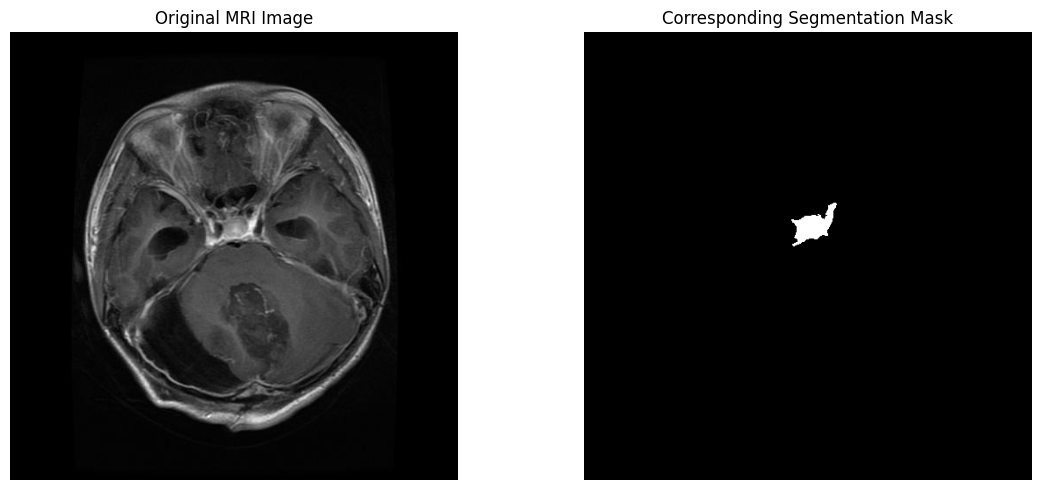

In [39]:
# Visually inspect one original segmentation MRI image and its corresponding mask.

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

sample_mask = mask_df.iloc[0]

mask_path = DATASET_ROOT / sample_mask["relative_path"].replace("\\", "/")
image_path = DATASET_ROOT / str(sample_mask["linked_image"]).replace("\\", "/")

with Image.open(image_path) as img:
    mri_array = np.array(img.convert("L"))

with Image.open(mask_path) as mask:
    mask_array = np.array(mask)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(mri_array, cmap="gray")
plt.title("Original MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_array, cmap="gray", vmin=0, vmax=255)
plt.title("Corresponding Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [40]:
# Identify exact SHA-256 duplicates in the classification dataset.

classification_df = manifest_df[
    manifest_df["task"] == "classification"
].copy()

print("CLASSIFICATION DUPLICATE HASH CHECK")
print("-" * 50)

print("Total classification records:", len(classification_df))

duplicate_hashes = classification_df[
    classification_df.duplicated(subset=["sha256"], keep=False)
].sort_values(["sha256", "split"])

print("Records involved in exact SHA-256 duplicates:",
      len(duplicate_hashes))

print("\nDuplicate records by split:")
if not duplicate_hashes.empty:
    display(
        duplicate_hashes[
            ["filename", "split", "tumor_label", "sha256"]
        ]
    )
else:
    print("No exact SHA-256 duplicates found.")

CLASSIFICATION DUPLICATE HASH CHECK
--------------------------------------------------
Total classification records: 6000
Records involved in exact SHA-256 duplicates: 96

Duplicate records by split:


,filename,split,tumor_label,sha256
826,brisc2025_test_00827_pi_co_t1.jpg,test,pituitary,02799f7863d49de182357e72179f3cc4e65e70099355f2...
5193,brisc2025_train_04194_pi_co_t1.jpg,train,pituitary,02799f7863d49de182357e72179f3cc4e65e70099355f2...
750,brisc2025_test_00751_pi_ax_t1.jpg,test,pituitary,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...
4748,brisc2025_train_03749_pi_ax_t1.jpg,train,pituitary,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...
4474,brisc2025_train_03475_no_sa_t1.jpg,train,no_tumor,092a6997f62fdbaa2bc49469a827ef799ebd70cc75d1b0...
...,...,...,...,...
2303,brisc2025_train_01304_me_ax_t1.jpg,train,meningioma,f3d00bbb942117c2fb62466414d3c466ca283b678200fe...
414,brisc2025_test_00415_me_co_t1.jpg,test,meningioma,f55311fb8ccf1b86450233262bd00b176bd1c404e5849b...
415,brisc2025_test_00416_me_co_t1.jpg,test,meningioma,f55311fb8ccf1b86450233262bd00b176bd1c404e5849b...
2570,brisc2025_train_01571_me_co_t1.jpg,train,meningioma,fce25282f9c298280721e6608db8dd49289984e7004b61...


In [41]:
# Categorize exact duplicate hash groups by their dataset splits.

duplicate_groups = (
    duplicate_hashes
    .groupby("sha256")
    .agg(
        record_count=("filename", "size"),
        splits=("split", lambda x: sorted(set(x))),
        filenames=("filename", list)
    )
    .reset_index()
)

duplicate_groups["duplicate_type"] = duplicate_groups["splits"].apply(
    lambda x: "Cross-split" if len(x) > 1
    else f"Within {x[0]}"
)

print("EXACT DUPLICATE GROUP SUMMARY")
print("-" * 50)
print("Total duplicate hash groups:", len(duplicate_groups))

print("\nDuplicate groups by type:")
display(duplicate_groups["duplicate_type"].value_counts())

print("\nCross-split duplicate groups:")
display(
    duplicate_groups[
        duplicate_groups["duplicate_type"] == "Cross-split"
    ]
)

EXACT DUPLICATE GROUP SUMMARY
--------------------------------------------------
Total duplicate hash groups: 46

Duplicate groups by type:


duplicate_type
Within train    34
Cross-split      7
Within test      5
Name: count, dtype: int64


Cross-split duplicate groups:


,sha256,record_count,splits,filenames,duplicate_type
0,02799f7863d49de182357e72179f3cc4e65e70099355f2...,2,"[test, train]","[brisc2025_test_00827_pi_co_t1.jpg, brisc2025_...",Cross-split
1,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,2,"[test, train]","[brisc2025_test_00751_pi_ax_t1.jpg, brisc2025_...",Cross-split
11,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...,2,"[test, train]","[brisc2025_test_00737_pi_ax_t1.jpg, brisc2025_...",Cross-split
12,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,4,"[test, train]","[brisc2025_test_00825_pi_co_t1.jpg, brisc2025_...",Cross-split
29,960155b05ea8f0ddcbcd3a5e29905c2a4b55832f03e5b7...,2,"[test, train]","[brisc2025_test_00344_me_ax_t1.jpg, brisc2025_...",Cross-split
34,b5e17076d1427e41a618f92bc72100c1be4df266082235...,2,"[test, train]","[brisc2025_test_00834_pi_co_t1.jpg, brisc2025_...",Cross-split
43,f3d00bbb942117c2fb62466414d3c466ca283b678200fe...,2,"[test, train]","[brisc2025_test_00352_me_ax_t1.jpg, brisc2025_...",Cross-split


In [42]:
# Count training and test records involved in exact cross-split duplicates.

cross_split_groups = duplicate_groups[
    duplicate_groups["duplicate_type"] == "Cross-split"
]

cross_split_hashes = cross_split_groups["sha256"]

cross_split_records = classification_df[
    classification_df["sha256"].isin(cross_split_hashes)
]

print("CROSS-SPLIT EXACT DUPLICATE SUMMARY")
print("-" * 50)

print("Duplicate hash groups:", len(cross_split_groups))
print("Total affected records:", len(cross_split_records))

print("\nAffected records by split:")
display(cross_split_records["split"].value_counts())

print("\nAffected records by class and split:")
display(
    cross_split_records.groupby(["split", "tumor_label"])
    .size()
    .unstack(fill_value=0)
)

CROSS-SPLIT EXACT DUPLICATE SUMMARY
--------------------------------------------------
Duplicate hash groups: 7
Total affected records: 16

Affected records by split:


split
train    9
test     7
Name: count, dtype: int64


Affected records by class and split:


tumor_label,meningioma,pituitary
split,,
test,2,5
train,2,7


In [43]:
# Identify exact duplicate hash groups occurring only within training.

train_duplicate_groups = duplicate_groups[
    duplicate_groups["duplicate_type"] == "Within train"
]

print("WITHIN-TRAIN EXACT DUPLICATES")
print("-" * 45)

print("Duplicate hash groups:", len(train_duplicate_groups))
print(
    "Total records involved:",
    train_duplicate_groups["record_count"].sum()
)

display(train_duplicate_groups)

WITHIN-TRAIN EXACT DUPLICATES
---------------------------------------------
Duplicate hash groups: 34
Total records involved: 70


,sha256,record_count,splits,filenames,duplicate_type
2,092a6997f62fdbaa2bc49469a827ef799ebd70cc75d1b0...,2,[train],"[brisc2025_train_03475_no_sa_t1.jpg, brisc2025...",Within train
3,09b9031e30e757eb6e648686f0ca412357e86895ebbc52...,2,[train],"[brisc2025_train_01276_me_ax_t1.jpg, brisc2025...",Within train
5,1105b29d6d5b9c2a3c59314b8fc63c661df43e488beb0d...,2,[train],"[brisc2025_train_01238_me_ax_t1.jpg, brisc2025...",Within train
6,1139856fed19589e9f95b7c059324c88a0e77baed54e8e...,2,[train],"[brisc2025_train_03477_no_sa_t1.jpg, brisc2025...",Within train
7,1e1a27e88f2812b4b950fca09bf5f4b8fe20514826756a...,2,[train],"[brisc2025_train_03471_no_sa_t1.jpg, brisc2025...",Within train
8,24f09f91af40e42f2798bbc29df353ce17e6a0c0b533fb...,3,[train],"[brisc2025_train_01247_me_ax_t1.jpg, brisc2025...",Within train
9,25dbc9664f03a7af82b74aec6c5497cd94dc5f6f639907...,2,[train],"[brisc2025_train_03489_no_sa_t1.jpg, brisc2025...",Within train
10,2c8be230a33c267864fdce27d56db309cd612981d9bb68...,2,[train],"[brisc2025_train_01251_me_ax_t1.jpg, brisc2025...",Within train
13,451f339dbf4d33864e0dd8940f533bbeddda6492cf60bb...,2,[train],"[brisc2025_train_02099_me_sa_t1.jpg, brisc2025...",Within train
14,4951f7ba2e002020c835b3f50136c3249f3ae004624b35...,2,[train],"[brisc2025_train_01246_me_ax_t1.jpg, brisc2025...",Within train


In [44]:
# Identify exact duplicate hash groups occurring only within training.

train_duplicate_groups = duplicate_groups[
    duplicate_groups["duplicate_type"] == "Within train"
]

print("WITHIN-TRAIN EXACT DUPLICATES")
print("-" * 45)

print("Duplicate hash groups:", len(train_duplicate_groups))
print(
    "Total records involved:",
    train_duplicate_groups["record_count"].sum()
)

display(train_duplicate_groups)

WITHIN-TRAIN EXACT DUPLICATES
---------------------------------------------
Duplicate hash groups: 34
Total records involved: 70


,sha256,record_count,splits,filenames,duplicate_type
2,092a6997f62fdbaa2bc49469a827ef799ebd70cc75d1b0...,2,[train],"[brisc2025_train_03475_no_sa_t1.jpg, brisc2025...",Within train
3,09b9031e30e757eb6e648686f0ca412357e86895ebbc52...,2,[train],"[brisc2025_train_01276_me_ax_t1.jpg, brisc2025...",Within train
5,1105b29d6d5b9c2a3c59314b8fc63c661df43e488beb0d...,2,[train],"[brisc2025_train_01238_me_ax_t1.jpg, brisc2025...",Within train
6,1139856fed19589e9f95b7c059324c88a0e77baed54e8e...,2,[train],"[brisc2025_train_03477_no_sa_t1.jpg, brisc2025...",Within train
7,1e1a27e88f2812b4b950fca09bf5f4b8fe20514826756a...,2,[train],"[brisc2025_train_03471_no_sa_t1.jpg, brisc2025...",Within train
8,24f09f91af40e42f2798bbc29df353ce17e6a0c0b533fb...,3,[train],"[brisc2025_train_01247_me_ax_t1.jpg, brisc2025...",Within train
9,25dbc9664f03a7af82b74aec6c5497cd94dc5f6f639907...,2,[train],"[brisc2025_train_03489_no_sa_t1.jpg, brisc2025...",Within train
10,2c8be230a33c267864fdce27d56db309cd612981d9bb68...,2,[train],"[brisc2025_train_01251_me_ax_t1.jpg, brisc2025...",Within train
13,451f339dbf4d33864e0dd8940f533bbeddda6492cf60bb...,2,[train],"[brisc2025_train_02099_me_sa_t1.jpg, brisc2025...",Within train
14,4951f7ba2e002020c835b3f50136c3249f3ae004624b35...,2,[train],"[brisc2025_train_01246_me_ax_t1.jpg, brisc2025...",Within train


In [45]:
# Print the total number of within-training exact duplicate groups and records.

print("Within-training duplicate groups:", len(train_duplicate_groups))
print(
    "Total training records involved:",
    train_duplicate_groups["record_count"].sum()
)
print(
    "Extra duplicate records:",
    train_duplicate_groups["record_count"].sum()
    - len(train_duplicate_groups)
)

Within-training duplicate groups: 34
Total training records involved: 70
Extra duplicate records: 36


In [46]:
# Identify exact duplicate hash groups occurring only within the test set.

test_duplicate_groups = duplicate_groups[
    duplicate_groups["duplicate_type"] == "Within test"
]

print("WITHIN-TEST EXACT DUPLICATES")
print("-" * 45)

print("Duplicate hash groups:", len(test_duplicate_groups))
print(
    "Total test records involved:",
    test_duplicate_groups["record_count"].sum()
)
print(
    "Extra duplicate records:",
    test_duplicate_groups["record_count"].sum()
    - len(test_duplicate_groups)
)

display(test_duplicate_groups)

WITHIN-TEST EXACT DUPLICATES
---------------------------------------------
Duplicate hash groups: 5
Total test records involved: 10
Extra duplicate records: 5


,sha256,record_count,splits,filenames,duplicate_type
4,0de951286256834bd2ddc4e26fe9795265fc200a9f7c85...,2,[test],"[brisc2025_test_00030_gl_ax_t1.jpg, brisc2025_...",Within test
22,86847c6a4729a4b19bf1b3f58905c68812c6f75ea680c0...,2,[test],"[brisc2025_test_00262_me_ax_t1.jpg, brisc2025_...",Within test
25,8d7abec740c4d59168bd40626034ce16cc2054a6b46cdf...,2,[test],"[brisc2025_test_00659_no_co_t1.jpg, brisc2025_...",Within test
28,94247e44617a135f0ce0ad29fcdff8c7bf484f3f2e4a98...,2,[test],"[brisc2025_test_00361_me_ax_t1.jpg, brisc2025_...",Within test
44,f55311fb8ccf1b86450233262bd00b176bd1c404e5849b...,2,[test],"[brisc2025_test_00415_me_co_t1.jpg, brisc2025_...",Within test


In [48]:
# Check how manifest paths are formatted and whether normalized paths exist.

sample_path = classification_df["relative_path"].iloc[0]

print("Original manifest path:")
print(repr(sample_path))

normalized_path = str(sample_path).replace("\\", "/")
image_path = DATASET_ROOT / normalized_path

print("\nNormalized path:")
print(image_path)

print("\nDoes the file exist?", image_path.exists())

Original manifest path:
'classification_task\\test\\glioma\\brisc2025_test_00001_gl_ax_t1.jpg'

Normalized path:
data/brisc2025/classification_task/test/glioma/brisc2025_test_00001_gl_ax_t1.jpg

Does the file exist? True


In [49]:
# Generate RGB pixel fingerprints using normalized macOS-compatible paths.

from PIL import Image
import hashlib

def get_rgb_fingerprint(relative_path):
    normalized_path = str(relative_path).replace("\\", "/")
    image_path = DATASET_ROOT / normalized_path

    with Image.open(image_path) as img:
        rgb_image = img.convert("RGB")
        return hashlib.sha256(rgb_image.tobytes()).hexdigest()

classification_pixel_df = classification_df.copy()

classification_pixel_df["rgb_fingerprint"] = (
    classification_pixel_df["relative_path"].apply(get_rgb_fingerprint)
)

print("Classification images checked:", len(classification_pixel_df))
print(
    "Decoded-image fingerprints generated:",
    classification_pixel_df["rgb_fingerprint"].notna().sum()
)

Classification images checked: 6000
Decoded-image fingerprints generated: 6000


In [50]:
# Group classification images that have identical decoded RGB pixel content.

rgb_duplicate_groups = (
    classification_pixel_df[
        classification_pixel_df.duplicated(
            subset=["rgb_fingerprint"], keep=False
        )
    ]
    .groupby("rgb_fingerprint")
    .agg(
        record_count=("filename", "size"),
        splits=("split", lambda x: sorted(set(x))),
        filenames=("filename", list),
        sha256_count=("sha256", "nunique")
    )
    .reset_index()
)

rgb_duplicate_groups["duplicate_type"] = rgb_duplicate_groups["splits"].apply(
    lambda x: "Cross-split" if len(x) > 1 else f"Within {x[0]}"
)

print("RGB PIXEL-IDENTICAL DUPLICATES")
print("-" * 45)
print("Duplicate groups:", len(rgb_duplicate_groups))
print("Total records involved:", rgb_duplicate_groups["record_count"].sum())
print(
    "Groups with different file hashes:",
    (rgb_duplicate_groups["sha256_count"] > 1).sum()
)

display(rgb_duplicate_groups)

RGB PIXEL-IDENTICAL DUPLICATES
---------------------------------------------
Duplicate groups: 134
Total records involved: 278
Groups with different file hashes: 94


,rgb_fingerprint,record_count,splits,filenames,sha256_count,duplicate_type
0,0c371b7e6641ef6b637cd25ebd2cefce7a83d7ba862006...,2,"[test, train]","[brisc2025_test_00323_me_ax_t1.jpg, brisc2025_...",2,Cross-split
1,0c866260d8bfd5756694bd80b326a32e00c77c7d5b5a50...,2,"[test, train]","[brisc2025_test_00482_me_sa_t1.jpg, brisc2025_...",2,Cross-split
2,0cae85be6ecdfd8c52f162a2793a12ac0497f9de5a7df9...,2,[train],"[brisc2025_train_01469_me_ax_t1.jpg, brisc2025...",1,Within train
3,0d2f6ea9ce9f93b8da0869748c9361c8822779ed695788...,2,"[test, train]","[brisc2025_test_00487_me_sa_t1.jpg, brisc2025_...",2,Cross-split
4,0fb5ceca0a3f5ee22c1ff4346804832cddfafee87c8c6f...,2,[train],"[brisc2025_train_04676_pi_sa_t1.jpg, brisc2025...",1,Within train
...,...,...,...,...,...,...
129,f6dcaa1cc493484f4e29a8697fc2c2954b525d8d7cb0fc...,2,"[test, train]","[brisc2025_test_00399_me_co_t1.jpg, brisc2025_...",2,Cross-split
130,f745f5610af7cfcfb15b53f7eb900cd3f8f6c24234b6e5...,2,"[test, train]","[brisc2025_test_00485_me_sa_t1.jpg, brisc2025_...",2,Cross-split
131,f7f9ac3d5a1d21b266e256701682176b48895603ea3ec9...,2,"[test, train]","[brisc2025_test_00290_me_ax_t1.jpg, brisc2025_...",2,Cross-split
132,fb57df49a25a37b181617c03af9553f84e2c833a5ce6e1...,2,"[test, train]","[brisc2025_test_00255_me_ax_t1.jpg, brisc2025_...",2,Cross-split


In [51]:
# Summarize RGB pixel-identical duplicate groups by split.

print("RGB DUPLICATE GROUPS BY TYPE")
print("-" * 45)

display(
    rgb_duplicate_groups.groupby("duplicate_type")
    .agg(
        duplicate_groups=("rgb_fingerprint", "count"),
        records_involved=("record_count", "sum")
    )
)

print("\nCROSS-SPLIT RGB DUPLICATES")
print("-" * 45)

rgb_cross_split_groups = rgb_duplicate_groups[
    rgb_duplicate_groups["duplicate_type"] == "Cross-split"
]

print("Cross-split duplicate groups:", len(rgb_cross_split_groups))
print(
    "Records involved:",
    rgb_cross_split_groups["record_count"].sum()
)

display(rgb_cross_split_groups)

RGB DUPLICATE GROUPS BY TYPE
---------------------------------------------


,duplicate_groups,records_involved
duplicate_type,,
Cross-split,98,205
Within test,5,10
Within train,31,63



CROSS-SPLIT RGB DUPLICATES
---------------------------------------------
Cross-split duplicate groups: 98
Records involved: 205


,rgb_fingerprint,record_count,splits,filenames,sha256_count,duplicate_type
0,0c371b7e6641ef6b637cd25ebd2cefce7a83d7ba862006...,2,"[test, train]","[brisc2025_test_00323_me_ax_t1.jpg, brisc2025_...",2,Cross-split
1,0c866260d8bfd5756694bd80b326a32e00c77c7d5b5a50...,2,"[test, train]","[brisc2025_test_00482_me_sa_t1.jpg, brisc2025_...",2,Cross-split
3,0d2f6ea9ce9f93b8da0869748c9361c8822779ed695788...,2,"[test, train]","[brisc2025_test_00487_me_sa_t1.jpg, brisc2025_...",2,Cross-split
5,0fe5c4f5e80feecc6341715ced7287a3392eda3ec25a6b...,2,"[test, train]","[brisc2025_test_00283_me_ax_t1.jpg, brisc2025_...",2,Cross-split
7,14276ff14a6b99b75afef23a0ee69d0a5d11175f22c2e8...,2,"[test, train]","[brisc2025_test_00401_me_co_t1.jpg, brisc2025_...",2,Cross-split
...,...,...,...,...,...,...
129,f6dcaa1cc493484f4e29a8697fc2c2954b525d8d7cb0fc...,2,"[test, train]","[brisc2025_test_00399_me_co_t1.jpg, brisc2025_...",2,Cross-split
130,f745f5610af7cfcfb15b53f7eb900cd3f8f6c24234b6e5...,2,"[test, train]","[brisc2025_test_00485_me_sa_t1.jpg, brisc2025_...",2,Cross-split
131,f7f9ac3d5a1d21b266e256701682176b48895603ea3ec9...,2,"[test, train]","[brisc2025_test_00290_me_ax_t1.jpg, brisc2025_...",2,Cross-split
132,fb57df49a25a37b181617c03af9553f84e2c833a5ce6e1...,2,"[test, train]","[brisc2025_test_00255_me_ax_t1.jpg, brisc2025_...",2,Cross-split


In [52]:
# Inspect the split-wise and class-wise distribution of cross-split RGB duplicates.

cross_split_fingerprints = rgb_cross_split_groups["rgb_fingerprint"]

rgb_cross_split_records = classification_pixel_df[
    classification_pixel_df["rgb_fingerprint"].isin(cross_split_fingerprints)
].copy()

print("CROSS-SPLIT RGB DUPLICATE SUMMARY")
print("-" * 45)

print("Total records:", len(rgb_cross_split_records))

print("\nRecords by split:")
display(rgb_cross_split_records["split"].value_counts())

print("\nRecords by class and split:")
display(
    rgb_cross_split_records.groupby(["split", "tumor_label"])
    .size()
    .unstack(fill_value=0)
)

CROSS-SPLIT RGB DUPLICATE SUMMARY
---------------------------------------------
Total records: 205

Records by split:


split
train    104
test     101
Name: count, dtype: int64


Records by class and split:


tumor_label,meningioma,pituitary
split,,
test,96,5
train,97,7


In [53]:
# Display the matching training and test filenames for each cross-split RGB duplicate group.

for fingerprint in cross_split_fingerprints:
    group = rgb_cross_split_records[
        rgb_cross_split_records["rgb_fingerprint"] == fingerprint
    ]

    train_files = group[group["split"] == "train"]["filename"].tolist()
    test_files = group[group["split"] == "test"]["filename"].tolist()

    print("\nTraining:", train_files)
    print("Test:", test_files)
    print("-" * 60)


Training: ['brisc2025_train_01253_me_ax_t1.jpg']
Test: ['brisc2025_test_00323_me_ax_t1.jpg']
------------------------------------------------------------

Training: ['brisc2025_train_02005_me_sa_t1.jpg']
Test: ['brisc2025_test_00482_me_sa_t1.jpg']
------------------------------------------------------------

Training: ['brisc2025_train_02010_me_sa_t1.jpg']
Test: ['brisc2025_test_00487_me_sa_t1.jpg']
------------------------------------------------------------

Training: ['brisc2025_train_01275_me_ax_t1.jpg']
Test: ['brisc2025_test_00283_me_ax_t1.jpg']
------------------------------------------------------------

Training: ['brisc2025_train_01659_me_co_t1.jpg']
Test: ['brisc2025_test_00401_me_co_t1.jpg']
------------------------------------------------------------

Training: ['brisc2025_train_01266_me_ax_t1.jpg']
Test: ['brisc2025_test_00273_me_ax_t1.jpg']
------------------------------------------------------------

Training: ['brisc2025_train_01285_me_ax_t1.jpg']
Test: ['brisc2025_te

In [55]:
# Install ImageHash for perceptual near-duplicate image detection.

%pip install ImageHash

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 1.1 MB/s  0:00:03m 1.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ImageHash]
Note: you may need to restart the kernel to use updated packages.


In [56]:
# Verify that ImageHash can now be imported.

import imagehash
print("ImageHash version:", imagehash.__version__)

ImageHash version: 4.3.2


In [57]:
# Generate perceptual hashes for all classification images.

import imagehash
from PIL import Image

def get_phash(relative_path):
    normalized_path = str(relative_path).replace("\\", "/")
    image_path = DATASET_ROOT / normalized_path

    with Image.open(image_path) as img:
        return str(imagehash.phash(img.convert("RGB")))

classification_pixel_df["phash"] = (
    classification_pixel_df["relative_path"].apply(get_phash)
)

print("Images processed:", len(classification_pixel_df))
print("Perceptual hashes generated:", classification_pixel_df["phash"].notna().sum())

display(classification_pixel_df[["filename", "split", "phash"]].head())

Images processed: 6000
Perceptual hashes generated: 6000


,filename,split,phash
0,brisc2025_test_00001_gl_ax_t1.jpg,test,93c62f3a6c6824cf
1,brisc2025_test_00002_gl_ax_t1.jpg,test,c2632b1c3c3c675b
2,brisc2025_test_00003_gl_ax_t1.jpg,test,c23a3de170cf638c
3,brisc2025_test_00004_gl_ax_t1.jpg,test,c3923f69648333cd
4,brisc2025_test_00005_gl_ax_t1.jpg,test,c2962f7934c730cd


In [2]:
# Restore the dataset paths, imports, and classification manifest.

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image
import imagehash

DATASET_ROOT = Path("data/brisc2025")
CLASSIFICATION_ROOT = DATASET_ROOT / "classification_task"
SEGMENTATION_ROOT = DATASET_ROOT / "segmentation_task"
MANIFEST_CSV = DATASET_ROOT / "manifest.csv"
MANIFEST_JSON = DATASET_ROOT / "manifest.json"

manifest_df = pd.read_csv(MANIFEST_CSV)

classification_df = manifest_df[
    manifest_df["task"] == "classification"
].copy()

print("Manifest shape:", manifest_df.shape)
print("Classification images:", len(classification_df))
print("Dataset folder exists:", DATASET_ROOT.exists())

Manifest shape: (15586, 16)
Classification images: 6000
Dataset folder exists: True


In [3]:
# Regenerate perceptual hashes for all 6,000 classification images.

from tqdm.auto import tqdm

def get_phash(relative_path):
    normalized_path = str(relative_path).replace("\\", "/")
    image_path = DATASET_ROOT / normalized_path

    with Image.open(image_path) as img:
        return str(imagehash.phash(img.convert("RGB")))

classification_pixel_df = classification_df.copy()

classification_pixel_df["phash"] = [
    get_phash(path)
    for path in tqdm(
        classification_pixel_df["relative_path"],
        desc="Generating pHashes"
    )
]

print("\nImages processed:", len(classification_pixel_df))
print("Missing pHashes:", classification_pixel_df["phash"].isna().sum())

display(classification_pixel_df[
    ["filename", "split", "tumor_label", "phash"]
].head())

/Users/krittikaroy/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating pHashes: 100%|█████████████████| 6000/6000 [00:05<00:00, 1016.82it/s]


Images processed: 6000
Missing pHashes: 0


,filename,split,tumor_label,phash
0,brisc2025_test_00001_gl_ax_t1.jpg,test,glioma,93c62f3a6c6824cf
1,brisc2025_test_00002_gl_ax_t1.jpg,test,glioma,c2632b1c3c3c675b
2,brisc2025_test_00003_gl_ax_t1.jpg,test,glioma,c23a3de170cf638c
3,brisc2025_test_00004_gl_ax_t1.jpg,test,glioma,c3923f69648333cd
4,brisc2025_test_00005_gl_ax_t1.jpg,test,glioma,c2962f7934c730cd


In [4]:
# Compare all pHash values using NumPy and identify pairs with Hamming distance <= 5.

import numpy as np

hash_values = np.array(
    [int(value, 16) for value in classification_pixel_df["phash"]],
    dtype=np.uint64
)

near_duplicate_pairs = []

for i in range(len(hash_values)):
    xor_values = np.bitwise_xor(hash_values[i], hash_values[i+1:])

    # Count the number of differing bits in each 64-bit hash.
    distances = np.zeros(len(xor_values), dtype=np.uint8)
    for shift in range(64):
        distances += ((xor_values >> shift) & 1).astype(np.uint8)

    matching_indices = np.where(distances <= 5)[0] + i + 1

    for j in matching_indices:
        near_duplicate_pairs.append({
            "filename_1": classification_pixel_df.iloc[i]["filename"],
            "split_1": classification_pixel_df.iloc[i]["split"],
            "class_1": classification_pixel_df.iloc[i]["tumor_label"],
            "filename_2": classification_pixel_df.iloc[j]["filename"],
            "split_2": classification_pixel_df.iloc[j]["split"],
            "class_2": classification_pixel_df.iloc[j]["tumor_label"],
            "hamming_distance": int(distances[j - i - 1])
        })

phash_candidates_df = pd.DataFrame(near_duplicate_pairs)

print("Near-duplicate candidate pairs:", len(phash_candidates_df))
display(phash_candidates_df.head(20))

Near-duplicate candidate pairs: 1349


,filename_1,split_1,class_1,filename_2,split_2,class_2,hamming_distance
0,brisc2025_test_00009_gl_ax_t1.jpg,test,glioma,brisc2025_train_00022_gl_ax_t1.jpg,train,glioma,2
1,brisc2025_test_00017_gl_ax_t1.jpg,test,glioma,brisc2025_test_00359_me_ax_t1.jpg,test,meningioma,4
2,brisc2025_test_00027_gl_ax_t1.jpg,test,glioma,brisc2025_train_00035_gl_ax_t1.jpg,train,glioma,2
3,brisc2025_test_00030_gl_ax_t1.jpg,test,glioma,brisc2025_test_00092_gl_co_t1.jpg,test,glioma,0
4,brisc2025_test_00036_gl_ax_t1.jpg,test,glioma,brisc2025_train_00041_gl_ax_t1.jpg,train,glioma,4
5,brisc2025_test_00037_gl_ax_t1.jpg,test,glioma,brisc2025_train_00042_gl_ax_t1.jpg,train,glioma,4
6,brisc2025_test_00039_gl_ax_t1.jpg,test,glioma,brisc2025_train_00049_gl_ax_t1.jpg,train,glioma,4
7,brisc2025_test_00040_gl_ax_t1.jpg,test,glioma,brisc2025_train_00061_gl_ax_t1.jpg,train,glioma,4
8,brisc2025_test_00043_gl_ax_t1.jpg,test,glioma,brisc2025_train_00068_gl_ax_t1.jpg,train,glioma,4
9,brisc2025_test_00044_gl_ax_t1.jpg,test,glioma,brisc2025_train_00089_gl_ax_t1.jpg,train,glioma,4


In [5]:
# Display the pHash comparison result and its summary.

print("Candidate pairs found:", len(phash_candidates_df))
print("Result columns:", phash_candidates_df.columns.tolist())

display(phash_candidates_df.head(10))

Candidate pairs found: 1349
Result columns: ['filename_1', 'split_1', 'class_1', 'filename_2', 'split_2', 'class_2', 'hamming_distance']


,filename_1,split_1,class_1,filename_2,split_2,class_2,hamming_distance
0,brisc2025_test_00009_gl_ax_t1.jpg,test,glioma,brisc2025_train_00022_gl_ax_t1.jpg,train,glioma,2
1,brisc2025_test_00017_gl_ax_t1.jpg,test,glioma,brisc2025_test_00359_me_ax_t1.jpg,test,meningioma,4
2,brisc2025_test_00027_gl_ax_t1.jpg,test,glioma,brisc2025_train_00035_gl_ax_t1.jpg,train,glioma,2
3,brisc2025_test_00030_gl_ax_t1.jpg,test,glioma,brisc2025_test_00092_gl_co_t1.jpg,test,glioma,0
4,brisc2025_test_00036_gl_ax_t1.jpg,test,glioma,brisc2025_train_00041_gl_ax_t1.jpg,train,glioma,4
5,brisc2025_test_00037_gl_ax_t1.jpg,test,glioma,brisc2025_train_00042_gl_ax_t1.jpg,train,glioma,4
6,brisc2025_test_00039_gl_ax_t1.jpg,test,glioma,brisc2025_train_00049_gl_ax_t1.jpg,train,glioma,4
7,brisc2025_test_00040_gl_ax_t1.jpg,test,glioma,brisc2025_train_00061_gl_ax_t1.jpg,train,glioma,4
8,brisc2025_test_00043_gl_ax_t1.jpg,test,glioma,brisc2025_train_00068_gl_ax_t1.jpg,train,glioma,4
9,brisc2025_test_00044_gl_ax_t1.jpg,test,glioma,brisc2025_train_00089_gl_ax_t1.jpg,train,glioma,4


In [6]:
# Categorize pHash near-duplicate pairs by dataset split.

phash_candidates_df["duplicate_type"] = np.where(
    phash_candidates_df["split_1"] != phash_candidates_df["split_2"],
    "Cross-split",
    "Within " + phash_candidates_df["split_1"]
)

print("Total near-duplicate pairs:", len(phash_candidates_df))

print("\nDuplicate type summary:")
display(
    phash_candidates_df["duplicate_type"]
    .value_counts()
    .rename_axis("Duplicate Type")
    .reset_index(name="Pair Count")
)

print("\nHamming distance distribution:")
display(
    phash_candidates_df["hamming_distance"]
    .value_counts()
    .sort_index()
    .rename_axis("Hamming Distance")
    .reset_index(name="Pair Count")
)

print("\nCross-split candidates:")
display(
    phash_candidates_df[
        phash_candidates_df["duplicate_type"] == "Cross-split"
    ].head(20)
)

Total near-duplicate pairs: 1349

Duplicate type summary:


,Duplicate Type,Pair Count
0,Within train,870
1,Cross-split,440
2,Within test,39



Hamming distance distribution:


,Hamming Distance,Pair Count
0,0,205
1,2,295
2,4,849



Cross-split candidates:


,filename_1,split_1,class_1,filename_2,split_2,class_2,hamming_distance,duplicate_type
0,brisc2025_test_00009_gl_ax_t1.jpg,test,glioma,brisc2025_train_00022_gl_ax_t1.jpg,train,glioma,2,Cross-split
2,brisc2025_test_00027_gl_ax_t1.jpg,test,glioma,brisc2025_train_00035_gl_ax_t1.jpg,train,glioma,2,Cross-split
4,brisc2025_test_00036_gl_ax_t1.jpg,test,glioma,brisc2025_train_00041_gl_ax_t1.jpg,train,glioma,4,Cross-split
5,brisc2025_test_00037_gl_ax_t1.jpg,test,glioma,brisc2025_train_00042_gl_ax_t1.jpg,train,glioma,4,Cross-split
6,brisc2025_test_00039_gl_ax_t1.jpg,test,glioma,brisc2025_train_00049_gl_ax_t1.jpg,train,glioma,4,Cross-split
7,brisc2025_test_00040_gl_ax_t1.jpg,test,glioma,brisc2025_train_00061_gl_ax_t1.jpg,train,glioma,4,Cross-split
8,brisc2025_test_00043_gl_ax_t1.jpg,test,glioma,brisc2025_train_00068_gl_ax_t1.jpg,train,glioma,4,Cross-split
9,brisc2025_test_00044_gl_ax_t1.jpg,test,glioma,brisc2025_train_00089_gl_ax_t1.jpg,train,glioma,4,Cross-split
10,brisc2025_test_00047_gl_ax_t1.jpg,test,glioma,brisc2025_train_00288_gl_ax_t1.jpg,train,glioma,4,Cross-split
11,brisc2025_test_00050_gl_ax_t1.jpg,test,glioma,brisc2025_train_00171_gl_ax_t1.jpg,train,glioma,4,Cross-split


In [7]:
# Summarize perceptual-hash candidates by split, class, and Hamming distance.

print("TOTAL NEAR-DUPLICATE PAIRS:", len(phash_candidates_df))

print("\n1. Candidate type distribution:")
display(
    phash_candidates_df["duplicate_type"]
    .value_counts()
    .rename_axis("Type")
    .reset_index(name="Count")
)

print("\n2. Cross-split candidates by class:")
cross_split_df = phash_candidates_df[
    phash_candidates_df["duplicate_type"] == "Cross-split"
]

display(
    cross_split_df.groupby(["class_1", "class_2"])
    .size()
    .reset_index(name="Candidate Pairs")
)

print("\n3. Hamming distance distribution:")
display(
    phash_candidates_df["hamming_distance"]
    .value_counts()
    .sort_index()
    .rename_axis("Distance")
    .reset_index(name="Count")
)

TOTAL NEAR-DUPLICATE PAIRS: 1349

1. Candidate type distribution:


,Type,Count
0,Within train,870
1,Cross-split,440
2,Within test,39



2. Cross-split candidates by class:


,class_1,class_2,Candidate Pairs
0,glioma,glioma,70
1,glioma,meningioma,2
2,meningioma,meningioma,195
3,no_tumor,meningioma,1
4,no_tumor,no_tumor,1
5,pituitary,pituitary,171



3. Hamming distance distribution:


,Distance,Count
0,0,205
1,2,295
2,4,849


In [8]:
# Display the complete pHash Hamming distance distribution from 0 to 5.

distance_summary = (
    phash_candidates_df["hamming_distance"]
    .value_counts()
    .reindex(range(6), fill_value=0)
    .rename_axis("Hamming Distance")
    .reset_index(name="Candidate Pairs")
)

display(distance_summary)

print("Total candidate pairs:", len(phash_candidates_df))

,Hamming Distance,Candidate Pairs
0,0,205
1,1,0
2,2,295
3,3,0
4,4,849
5,5,0


Total candidate pairs: 1349


Total cross-split candidate pairs: 440
Displaying pairs: 10


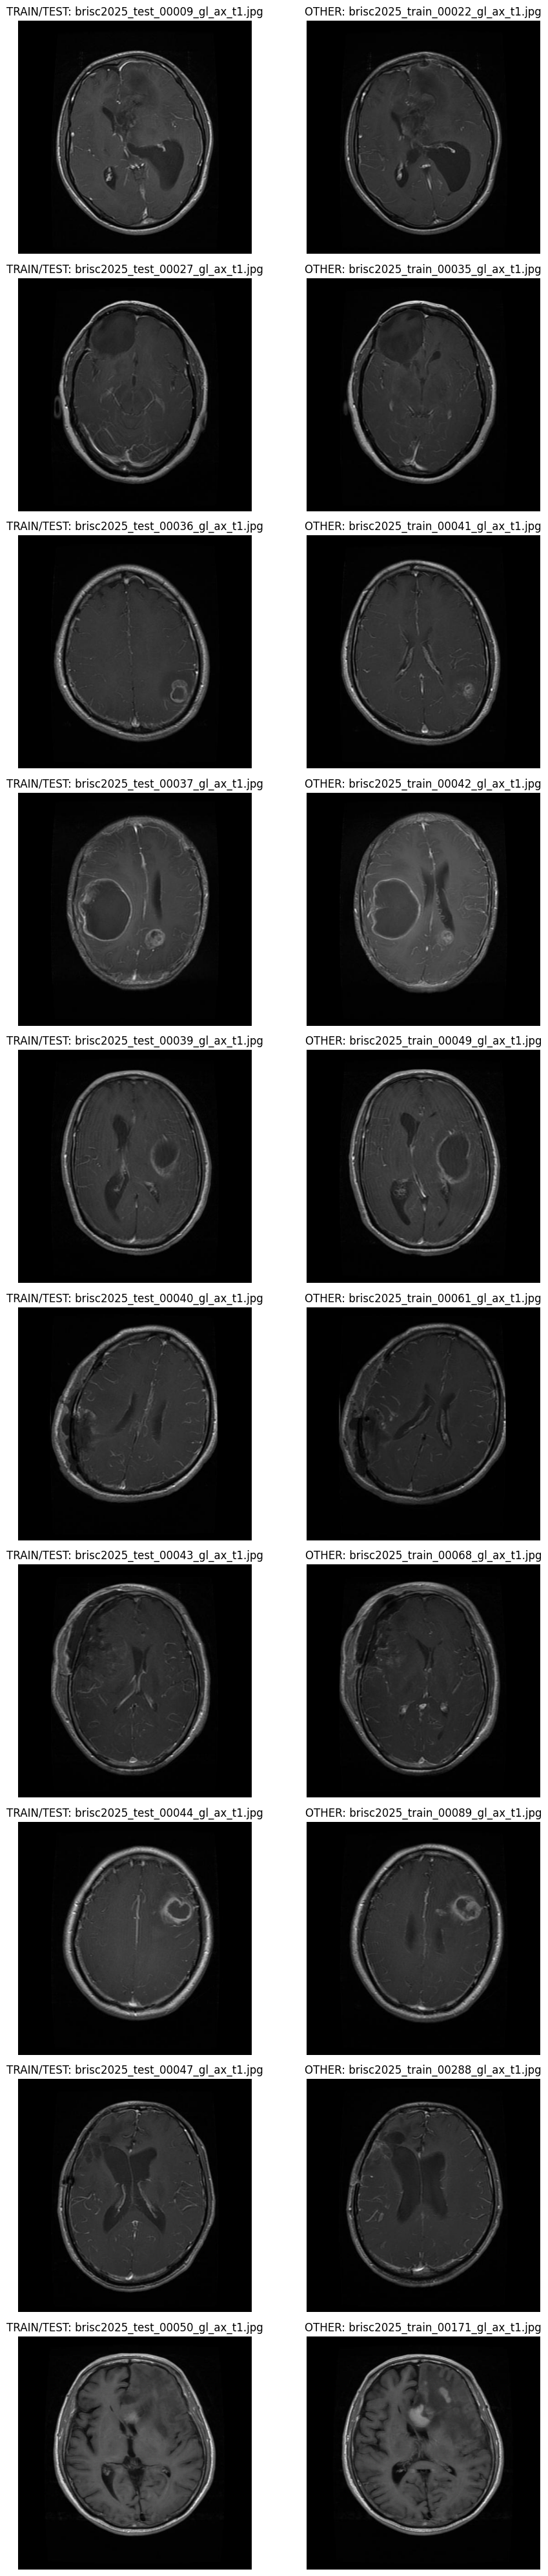

In [9]:
# Display the first 10 cross-split pHash candidate pairs for visual inspection.

import matplotlib.pyplot as plt
from PIL import Image

cross_split_df = phash_candidates_df[
    phash_candidates_df["duplicate_type"] == "Cross-split"
].copy()

path_lookup = dict(zip(
    classification_pixel_df["filename"],
    classification_pixel_df["relative_path"]
))

sample_pairs = cross_split_df.head(10)

print("Total cross-split candidate pairs:", len(cross_split_df))
print("Displaying pairs:", len(sample_pairs))

fig, axes = plt.subplots(len(sample_pairs), 2, figsize=(10, 4 * len(sample_pairs)))

if len(sample_pairs) == 1:
    axes = np.array([axes])

for row, (_, pair) in enumerate(sample_pairs.iterrows()):
    path1 = DATASET_ROOT / str(path_lookup[pair["filename_1"]]).replace("\\", "/")
    path2 = DATASET_ROOT / str(path_lookup[pair["filename_2"]]).replace("\\", "/")

    with Image.open(path1) as img1:
        axes[row, 0].imshow(img1.convert("RGB"))
    with Image.open(path2) as img2:
        axes[row, 1].imshow(img2.convert("RGB"))

    axes[row, 0].set_title(f'TRAIN/TEST: {pair["filename_1"]}')
    axes[row, 1].set_title(f'OTHER: {pair["filename_2"]}')

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [10]:
# Count unique training and test images involved in cross-split pHash candidates.

print("Cross-split candidate pairs:", len(cross_split_df))

print(
    "Unique test images involved:",
    cross_split_df["filename_1"].nunique()
)

print(
    "Unique training images involved:",
    cross_split_df["filename_2"].nunique()
)

print(
    "Hamming distance range:",
    cross_split_df["hamming_distance"].min(),
    "to",
    cross_split_df["hamming_distance"].max()
)

print("\nCandidate pairs by Hamming distance:")
display(
    cross_split_df["hamming_distance"]
    .value_counts()
    .sort_index()
    .rename_axis("Distance")
    .reset_index(name="Pairs")
)

Cross-split candidate pairs: 440
Unique test images involved: 324
Unique training images involved: 398
Hamming distance range: 0 to 4

Candidate pairs by Hamming distance:


,Distance,Pairs
0,0,128
1,2,85
2,4,227


In [11]:
# Extract cross-split candidates with identical perceptual hashes.

phash_exact_candidates = cross_split_df[
    cross_split_df["hamming_distance"] == 0
].copy()

print("Cross-split pairs with identical pHashes:", len(phash_exact_candidates))

display(
    phash_exact_candidates[
        ["filename_1", "filename_2", "class_1", "class_2", "hamming_distance"]
    ].head(20)
)

Cross-split pairs with identical pHashes: 128


,filename_1,filename_2,class_1,class_2,hamming_distance
79,brisc2025_test_00255_me_ax_t1.jpg,brisc2025_train_01261_me_ax_t1.jpg,meningioma,meningioma,0
83,brisc2025_test_00257_me_ax_t1.jpg,brisc2025_train_01256_me_ax_t1.jpg,meningioma,meningioma,0
85,brisc2025_test_00257_me_ax_t1.jpg,brisc2025_train_01402_me_ax_t1.jpg,meningioma,meningioma,0
86,brisc2025_test_00258_me_ax_t1.jpg,brisc2025_train_01379_me_ax_t1.jpg,meningioma,meningioma,0
87,brisc2025_test_00259_me_ax_t1.jpg,brisc2025_train_01381_me_ax_t1.jpg,meningioma,meningioma,0
88,brisc2025_test_00260_me_ax_t1.jpg,brisc2025_train_01383_me_ax_t1.jpg,meningioma,meningioma,0
91,brisc2025_test_00261_me_ax_t1.jpg,brisc2025_train_01384_me_ax_t1.jpg,meningioma,meningioma,0
93,brisc2025_test_00262_me_ax_t1.jpg,brisc2025_train_01247_me_ax_t1.jpg,meningioma,meningioma,0
94,brisc2025_test_00262_me_ax_t1.jpg,brisc2025_train_01268_me_ax_t1.jpg,meningioma,meningioma,0
95,brisc2025_test_00262_me_ax_t1.jpg,brisc2025_train_01386_me_ax_t1.jpg,meningioma,meningioma,0


In [12]:
# Check exact SHA-256 overlap between segmentation training and test images and masks.

seg_df = manifest_df[manifest_df["task"] == "segmentation"].copy()

for mask_status, label in [(False, "MRI images"), (True, "Masks")]:
    subset = seg_df[seg_df["is_mask"] == mask_status]

    train_hashes = set(
        subset.loc[subset["split"] == "train", "sha256"]
    )
    test_hashes = set(
        subset.loc[subset["split"] == "test", "sha256"]
    )

    overlap = train_hashes.intersection(test_hashes)

    print(f"\n{label}")
    print("Training unique hashes:", len(train_hashes))
    print("Test unique hashes:", len(test_hashes))
    print("Cross-split exact hash overlaps:", len(overlap))


MRI images
Training unique hashes: 3904
Test unique hashes: 856
Cross-split exact hash overlaps: 7

Masks
Training unique hashes: 3918
Test unique hashes: 858
Cross-split exact hash overlaps: 0


In [13]:
# List the segmentation MRI files whose SHA-256 hashes occur in both splits.

seg_images = seg_df[seg_df["is_mask"] == False].copy()

train_seg = seg_images[seg_images["split"] == "train"]
test_seg = seg_images[seg_images["split"] == "test"]

overlap_hashes = (
    set(train_seg["sha256"]) & set(test_seg["sha256"])
)

for hash_value in sorted(overlap_hashes):
    print("\nMatching SHA-256:", hash_value)

    print("TRAIN:")
    display(
        train_seg.loc[
            train_seg["sha256"] == hash_value,
            ["filename", "relative_path"]
        ]
    )

    print("TEST:")
    display(
        test_seg.loc[
            test_seg["sha256"] == hash_value,
            ["filename", "relative_path"]
        ]
    )


Matching SHA-256: 02799f7863d49de182357e72179f3cc4e65e70099355f2d5aa2e39d356e492d9
TRAIN:


,filename,relative_path
10846,brisc2025_train_04194_pi_co_t1.jpg,segmentation_task\train\images\brisc2025_train...


TEST:


,filename,relative_path
6686,brisc2025_test_00827_pi_co_t1.jpg,segmentation_task\test\images\brisc2025_test_0...



Matching SHA-256: 08690b76457b2b44d58682cece62ec951ef6d30d935ce07df852e97d44434680
TRAIN:


,filename,relative_path
10401,brisc2025_train_03749_pi_ax_t1.jpg,segmentation_task\train\images\brisc2025_train...


... (18 outputs left out)


Matching SHA-256: f3d00bbb942117c2fb62466414d3c466ca283b678200fe87424e4128b80b2dba
TRAIN:


,filename,relative_path
9023,brisc2025_train_01304_me_ax_t1.jpg,segmentation_task\train\images\brisc2025_train...


TEST:


,filename,relative_path
6351,brisc2025_test_00352_me_ax_t1.jpg,segmentation_task\test\images\brisc2025_test_0...


In [14]:
# Identify and record exact cross-split segmentation MRI and mask duplicates.

seg_df = manifest_df[manifest_df["task"] == "segmentation"].copy()

for mask_status, label in [(False, "MRI IMAGES"), (True, "MASKS")]:
    subset = seg_df[seg_df["is_mask"] == mask_status]

    train = subset[subset["split"] == "train"]
    test = subset[subset["split"] == "test"]

    overlap = set(train["sha256"]) & set(test["sha256"])

    print(f"\n{label}")
    print("Exact cross-split hash overlaps:", len(overlap))

    if overlap:
        matches = subset[subset["sha256"].isin(overlap)]
        display(matches[["filename", "split", "sha256"]])


MRI IMAGES
Exact cross-split hash overlaps: 7


,filename,split,sha256
6343,brisc2025_test_00344_me_ax_t1.jpg,test,960155b05ea8f0ddcbcd3a5e29905c2a4b55832f03e5b7...
6351,brisc2025_test_00352_me_ax_t1.jpg,test,f3d00bbb942117c2fb62466414d3c466ca283b678200fe...
6596,brisc2025_test_00737_pi_ax_t1.jpg,test,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...
6610,brisc2025_test_00751_pi_ax_t1.jpg,test,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...
6684,brisc2025_test_00825_pi_co_t1.jpg,test,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...
6686,brisc2025_test_00827_pi_co_t1.jpg,test,02799f7863d49de182357e72179f3cc4e65e70099355f2...
6693,brisc2025_test_00834_pi_co_t1.jpg,test,b5e17076d1427e41a618f92bc72100c1be4df266082235...
8929,brisc2025_train_01210_me_ax_t1.jpg,train,960155b05ea8f0ddcbcd3a5e29905c2a4b55832f03e5b7...
9023,brisc2025_train_01304_me_ax_t1.jpg,train,f3d00bbb942117c2fb62466414d3c466ca283b678200fe...
10357,brisc2025_train_03705_pi_ax_t1.jpg,train,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...



MASKS
Exact cross-split hash overlaps: 0


In [16]:
# Create a final summary using the verified BRISC dataset audit results.

import pandas as pd

audit_summary = pd.DataFrame([
    ["Manifest records", 15586, "Verified"],
    ["Missing files", 0, "Passed"],
    ["Extra files", 0, "Passed"],
    ["File size mismatches", 0, "Passed"],
    ["Image dimension mismatches", 0, "Passed"],
    ["Unreadable images", 0, "Passed"],
    ["Dataset SHA-256 mismatches", 0, "Passed"],
    ["Segmentation MRI-mask pairs", 4793, "Verified"],
    ["Missing or invalid mask links", 0, "Passed"],
    ["Segmentation pair dimension mismatches", 0, "Passed"],
    ["Classification exact duplicate groups", 46, "Detected"],
    ["Classification RGB duplicate groups", 134, "Detected"],
    ["Classification pHash candidate pairs", 1349, "Requires review"],
    ["Classification cross-split pHash pairs", 440, "Requires review"],
    ["Segmentation MRI cross-split hash overlaps", 7, "Requires review"],
    ["Segmentation mask cross-split hash overlaps", 0, "No exact overlap"]
], columns=["Audit Check", "Result", "Status"])

display(audit_summary)

print("\nBRISC DATASET INTEGRITY AUDIT COMPLETED")
print("Original dataset files were not modified.")

,Audit Check,Result,Status
0,Manifest records,15586,Verified
1,Missing files,0,Passed
2,Extra files,0,Passed
3,File size mismatches,0,Passed
4,Image dimension mismatches,0,Passed
5,Unreadable images,0,Passed
6,Dataset SHA-256 mismatches,0,Passed
7,Segmentation MRI-mask pairs,4793,Verified
8,Missing or invalid mask links,0,Passed
9,Segmentation pair dimension mismatches,0,Passed



BRISC DATASET INTEGRITY AUDIT COMPLETED
Original dataset files were not modified.


In [ ]:
# Notebook 02 – BRISC Dataset Integrity and Leakage Checks

## 1. Objective

The objective of this notebook was to verify the integrity and consistency of the BRISC 2025 dataset, validate the supplied manifest and checksums, investigate duplicate images, identify potential train-test data leakage, and verify segmentation mask integrity.

## 2. Manifest Structure and Verification

Loaded and inspected the supplied BRISC manifest.

- Total records: 15,586
- Total columns: 16
- Duplicate column names: 0
- Duplicate relative paths: 0

The manifest contained dataset metadata including filenames, tasks, splits, tumor labels, MRI planes, image dimensions, file sizes and SHA-256 hashes.

The CSV and JSON manifest checksums were verified against their supplied checksum files.

Both checksum verifications matched successfully.

## 3. Dataset File Integrity

Performed the following verification checks:

- File existence verification.
- Actual dataset files versus manifest comparison.
- File size verification.
- Image dimension verification.
- Image readability verification.
- SHA-256 verification of all dataset files.

**Results:**
- Manifest records: 15,586
- Missing files: 0
- Extra files: 0
- File size mismatches: 0
- Image dimension mismatches: 0
- Unreadable images: 0
- SHA-256 mismatches: 0

All 15,586 dataset files matched their manifest records and recorded checksums.

## 4. Segmentation Integrity Checks

Verified the relationship between segmentation MRI images and their corresponding masks.

- MRI images: 4,793
- Masks: 4,793
- Missing mask links: 0
- Invalid mask links: 0
- Dimension mismatches: 0

The pixel values of all masks were inspected.

A total of 21 distinct values were identified, ranging from 0–10 and 246–255.

A representative MRI-mask pair was also visually inspected.

The original masks were inspected but not thresholded, converted or overwritten during the integrity audit.

## 5. Classification Duplicate and Leakage Analysis

### A. Exact Duplicate Detection Using SHA-256

Compared SHA-256 hashes to identify identical files within and across the official dataset splits.

**Results:**
- Total duplicate groups: 46
- Records involved: 96
- Within-training duplicate groups: 34 groups involving 70 records.
- Within-testing duplicate groups: 5 groups involving 10 records.
- Cross-split duplicate groups: 7 groups involving 16 records.

The cross-split groups included 9 training records and 7 testing records, affecting the meningioma and pituitary classes.

### B. Decoded RGB Pixel-Identical Duplicate Detection

Generated decoded RGB pixel fingerprints for all 6,000 classification images.

This additional check identified identical image content even when the original file hashes differed.

**Results:**
- RGB-identical duplicate groups: 134
- Records involved: 278
- Cross-split duplicate groups: 98
- Cross-split records involved: 205
- Affected training records: 104
- Affected testing records: 101
- Groups with different file hashes: 94

### C. Perceptual Hash (pHash) Analysis

Generated perceptual hashes for all 6,000 classification images using ImageHash 4.3.2.

Compared image pairs using a Hamming distance threshold of 5 or less.

**Results:**
- Total candidate pairs: 1,349
- Within-training candidates: 870
- Within-testing candidates: 39
- Cross-split candidates: 440

The 440 cross-split candidates involved:
- 324 unique test images.
- 398 unique training images.

Perceptual similarity was treated as a candidate indicator, not proof of an identical image.

## 6. Segmentation Train-Test Overlap Analysis

Compared SHA-256 hashes of segmentation MRI images and masks across the official training and testing splits.

**MRI image results:**
- Unique training hashes: 3,904
- Unique testing hashes: 856
- Cross-split exact hash overlaps: 7

**Mask results:**
- Unique training hashes: 3,918
- Unique testing hashes: 858
- Cross-split exact hash overlaps: 0

Seven exact-hash overlaps were detected among segmentation MRI images. These matches were flagged for further investigation. No exact cross-split mask overlap was detected.

## 7. Dataset Preservation and Limitations

- Original dataset files were not modified or deleted.
- The official test split was preserved.
- Duplicate and potential leakage findings were documented rather than silently removed.
- Perceptual-hash candidates were not automatically treated as confirmed duplicates.
- Patient-level independence could not be conclusively established because reliable patient identifiers were unavailable.

## 8. Conclusion

The BRISC 2025 dataset underwent a comprehensive integrity and duplicate-content audit.

The manifest, file existence, checksums, image dimensions, readability and segmentation MRI-mask relationships were successfully verified.

The duplicate analysis identified exact file duplicates, decoded RGB pixel-identical duplicates and perceptual-hash similarity candidates across the classification dataset.

The segmentation audit also identified seven exact-hash overlaps among MRI images across the official training and testing splits, while no exact mask overlap was found.

These findings provide important information about dataset quality, duplicate-related contamination and potential data leakage that must be considered during subsequent split preparation and model evaluation.

The original dataset and official test split were preserved throughout the audit.